# Dropout: Teaching a Network Not to Memorise
## A controlled Fashion-MNIST experiment with PyTorch Lightning

**Research question:** How does changing the dropout probability affect overfitting and validation performance in a small convolutional neural network (CNN) trained on Fashion-MNIST?

This notebook follows the structure and terminology of the supplied `Hyperparameters (SUper saiyanFinal).ipynb` reference: a central `HParams` dataclass, Fashion-MNIST data handling, a small CNN, and a PyTorch Lightning training module. It narrows the broader hyperparameter tutorial to one controlled question: **dropout probability**.

**Academic integrity:** The notebook generates metrics and figures when you run it. Do not report example, assumed, or fabricated values. Interpret the results produced by your own run, and disclose AI assistance as required by your course.


## 1. Research design and controlled variables

| Component | Fixed specification |
|---|---|
| Dataset | Fashion-MNIST |
| Split | Official 60,000-image training split → 54,000 training + 6,000 validation; official test split held out |
| Model | CNN: two convolutional blocks, followed by a classifier head |
| Convolution channels | 32 and 64 |
| Hidden dimension | 128 |
| Activation | ReLU |
| Batch normalization | Enabled |
| Dropout probabilities | 0.0, 0.2, 0.5, 0.7 |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Epochs | 15 |
| Seed | 42 |
| Loss | Cross-entropy |
| Main outcomes | Training loss, validation loss, validation accuracy by epoch |

**Controlled-comparison principle:** dropout probability is the only planned change between configurations. The data split, architecture, optimizer, learning rate, batch size, number of epochs, and seed remain fixed.

**Important limitation:** one seed provides a manageable initial experiment, not a definitive estimate of performance. For a stronger follow-up, repeat each dropout setting with several seeds and report mean ± standard deviation. The validation set is used for comparisons; the official test set is not used to select the dropout setting.


## 2. Install dependencies

Run this cell if the environment does not already have the required packages. The code uses the same core stack as the reference notebook: PyTorch, torchvision, PyTorch Lightning, pandas, and matplotlib.

In [ ]:
%pip install -q torch torchvision lightning pandas matplotlib

## 3. Imports, configuration, and reproducibility

In [ ]:
import random
import time
import platform
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import lightning as L
from lightning.pytorch.callbacks import Callback

@dataclass
class HParams:
    # Data
    data_dir: str = "./data"
    batch_size: int = 64
    val_fraction: float = 0.1
    train_subset: int | None = None  # None = use all available training examples
    augment: bool = False
    num_workers: int = 0

    # CNN architecture
    conv1_channels: int = 32
    conv2_channels: int = 64
    hidden_dim: int = 128
    activation: str = "relu"
    use_batchnorm: bool = True
    dropout: float = 0.25

    # Optimization
    optimizer: str = "adam"
    lr: float = 1e-3
    momentum: float = 0.9
    weight_decay: float = 0.0
    scheduler: str = "none"

    # Training
    max_epochs: int = 15
    patience: int = 100  # disable early stopping for equal epoch counts
    seed: int = 42

BASE_HP = HParams()
DROPOUT_VALUES = [0.0, 0.2, 0.5, 0.7]
OUTPUT_DIR = Path("dropout_experiment_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Lightning:", L.__version__)
print("CUDA available:", torch.cuda.is_available())
pd.Series(asdict(BASE_HP), name="value").to_frame()


Python: 3.13.18
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Lightning: 2.6.6
CUDA available: False


,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,None
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


## 4. Fashion-MNIST data module

Fashion-MNIST contains 28×28 grayscale images across ten clothing categories. A deterministic split is created from the official training split. The validation set uses evaluation transforms, so random augmentation (if enabled in a future experiment) does not alter validation examples.

For the main dropout experiment, augmentation is disabled to avoid introducing another changing factor.

In [ ]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)

class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])

        augmentations = []
        if hp.augment:
            augmentations = [
                transforms.RandomCrop(28, padding=2),
                transforms.RandomHorizontalFlip()
            ]
        self.train_transform = transforms.Compose([
            *augmentations, transforms.ToTensor(), normalize
        ])

    def prepare_data(self):
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        train_view = datasets.FashionMNIST(
            self.hp.data_dir, train=True, transform=self.train_transform
        )
        eval_view = datasets.FashionMNIST(
            self.hp.data_dir, train=True, transform=self.eval_transform
        )
        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_indices, train_indices = indices[:n_val], indices[n_val:]

        if self.hp.train_subset is not None:
            if not 1 <= self.hp.train_subset <= len(train_indices):
                raise ValueError("train_subset must be within the available training split.")
            train_indices = train_indices[:self.hp.train_subset]

        self.train_ds = Subset(train_view, train_indices)
        self.val_ds = Subset(eval_view, val_indices)
        self.test_ds = datasets.FashionMNIST(
            self.hp.data_dir, train=False, transform=self.eval_transform
        )

    def _loader(self, dataset, batch_size, shuffle):
        generator = torch.Generator().manual_seed(self.hp.seed)
        return DataLoader(
            dataset, batch_size=batch_size, shuffle=shuffle,
            num_workers=self.hp.num_workers,
            persistent_workers=self.hp.num_workers > 0,
            generator=generator if shuffle else None,
            pin_memory=torch.cuda.is_available()
        )

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

dm_preview = FashionMNISTDataModule(BASE_HP)
dm_preview.prepare_data()
dm_preview.setup()
print(f"Training examples: {len(dm_preview.train_ds):,}")
print(f"Validation examples: {len(dm_preview.val_ds):,}")
print(f"Held-out test examples: {len(dm_preview.test_ds):,}")
print("Classes:", CLASS_NAMES)


100%|██████████| 26.4M/26.4M [00:01<00:00, 17.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 270kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.5MB/s]


Training examples: 54,000
Validation examples: 6,000
Held-out test examples: 10,000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 5. Inspect the dataset

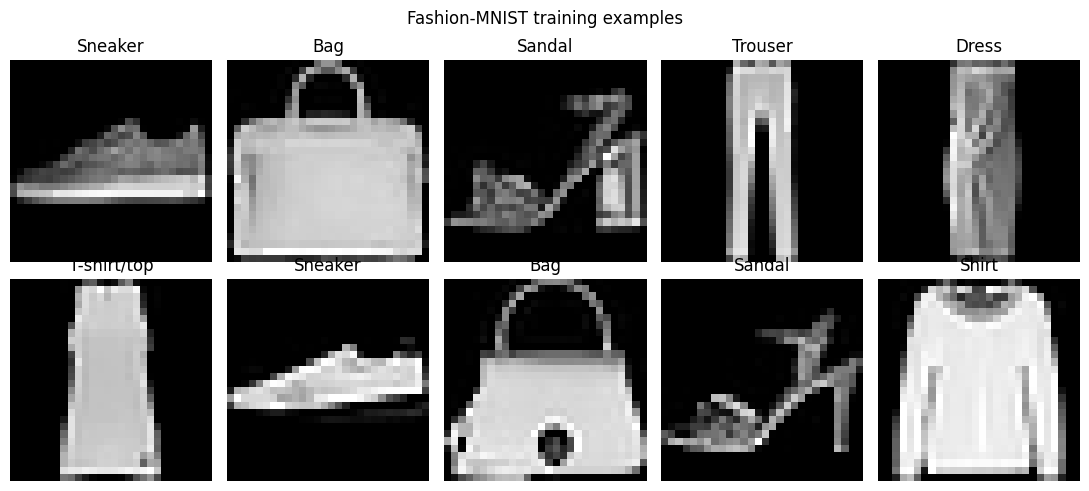

In [ ]:
images, labels = next(iter(dm_preview.train_dataloader()))
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    # Undo normalization for display.
    shown = image.squeeze(0) * FMNIST_STD[0] + FMNIST_MEAN[0]
    ax.imshow(shown, cmap="gray")
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis("off")
fig.suptitle("Fashion-MNIST training examples")
plt.tight_layout()
plt.show()


## 6. CNN model: where dropout is applied

The model follows the reference notebook's `SmallCNN` design. Two convolutional blocks extract image features. The classifier then flattens those features, applies dropout, maps them to a hidden representation, applies dropout again, and produces ten class logits.

The dropout probability `p` controls the chance that an activation is set to zero during training. PyTorch's dropout layer is automatically disabled during evaluation. The architecture is held fixed in every run; only `hp.dropout` changes.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "gelu": nn.GELU,
    "tanh": nn.Tanh
}

class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]

        def conv_block(in_channels, out_channels):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
            if hp.use_batchnorm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.extend([act(), nn.MaxPool2d(2)])
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            conv_block(1, hp.conv1_channels),
            conv_block(hp.conv1_channels, hp.conv2_channels)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=hp.dropout),
            nn.Linear(hp.conv2_channels * 7 * 7, hp.hidden_dim),
            act(),
            nn.Dropout(p=hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

preview_model = SmallCNN(BASE_HP)
print(preview_model)
print(f"Trainable parameters: {count_parameters(preview_model):,}")


SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 421,834


## 7. PyTorch Lightning module and epoch metric recording

In [ ]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True,
                 prog_bar=False, batch_size=len(y))
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True,
                 prog_bar=False, batch_size=len(y))
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def configure_optimizers(self):
        hp = self.hp
        if hp.optimizer == "adam":
            optimizer = torch.optim.Adam(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "sgd":
            optimizer = torch.optim.SGD(self.parameters(), lr=hp.lr, momentum=hp.momentum,
                                        weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"Unknown optimizer: {hp.optimizer}")

        if hp.scheduler == "none":
            return optimizer
        if hp.scheduler == "step":
            scheduler = torch.optim.lr_scheduler.StepLR(
                optimizer, step_size=max(1, hp.max_epochs // 3), gamma=0.1
            )
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp.max_epochs)
        else:
            raise ValueError(f"Unknown scheduler: {hp.scheduler}")
        return {"optimizer": optimizer,
                "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}


class EpochMetricsRecorder(Callback):
    """Collect epoch-level metrics from Lightning's callback_metrics."""
    def __init__(self):
        super().__init__()
        self.rows = []

    def on_validation_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics
        row = {"epoch": int(trainer.current_epoch + 1)}
        for name in ("train_loss", "train_acc", "val_loss", "val_acc"):
            value = metrics.get(name)
            row[name] = float(value.detach().cpu()) if value is not None else np.nan
        self.rows.append(row)


## 8. Fit helper and controlled runs

Early stopping is intentionally disabled for this comparison (`patience=100`) so all settings run for the same number of epochs. This prevents one configuration from receiving a different training budget. If a run fails, fix the underlying issue and rerun; do not manually edit the outputs.

In [ ]:
def fit_dropout_config(hp: HParams, run_name: str):
    L.seed_everything(hp.seed, workers=True)
    dm = FashionMNISTDataModule(hp)
    recorder = EpochMetricsRecorder()
    model = LitClassifier(hp)

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,
        accelerator="auto",
        devices=1,
        deterministic=True,
        logger=False,
        callbacks=[recorder],
        enable_checkpointing=False,
        enable_progress_bar=True,
        enable_model_summary=False,
        num_sanity_val_steps=0,
        log_every_n_steps=50,
    )
    start = time.perf_counter()
    trainer.fit(model, datamodule=dm)
    elapsed = time.perf_counter() - start
    history = pd.DataFrame(recorder.rows)
    history["dropout"] = hp.dropout
    history["run_name"] = run_name
    return model, trainer, dm, history, elapsed


## 9. Run the experiment

The four runs share the same seed and fixed configuration. Only `dropout` changes. The validation set is used for comparison. If you need a quick software check before a full run, set `train_subset=10000` in `BASE_HP` and disclose that reduced subset in your post; the default below uses the full training split.

In [ ]:
# Main experiment: full training split, 15 epochs.
# For a quick smoke test only, change train_subset=None to train_subset=10000.
BASE_HP = HParams(
    batch_size=64,
    val_fraction=0.1,
    train_subset=10000,
    augment=False,
    conv1_channels=32,
    conv2_channels=64,
    hidden_dim=128,
    activation="relu",
    use_batchnorm=True,
    optimizer="adam",
    lr=1e-3,
    momentum=0.9,
    weight_decay=0.0,
    scheduler="none",
    max_epochs=5,
    patience=100,
    seed=42,
)

histories = {}
summary_rows = []
start_all = time.perf_counter()

for p in DROPOUT_VALUES:
    hp_run = replace(BASE_HP, dropout=p)
    print(f"\n{'='*60}\nRun: dropout={p:.1f}\n{'='*60}")
    model, trainer, dm, history, seconds = fit_dropout_config(hp_run, f"dropout_{p:.1f}")
    histories[p] = history

    best_idx = history["val_acc"].idxmax()
    best = history.loc[best_idx]
    final = history.iloc[-1]
    summary_rows.append({
        "dropout": p,
        "best_epoch_by_val_accuracy": int(best["epoch"]),
        "best_val_accuracy": float(best["val_acc"]),
        "val_loss_at_best_accuracy": float(best["val_loss"]),
        "final_train_loss": float(final["train_loss"]),
        "final_train_accuracy": float(final["train_acc"]),
        "final_val_loss": float(final["val_loss"]),
        "final_val_accuracy": float(final["val_acc"]),
        "epochs_completed": len(history),
        "training_seconds": round(seconds, 1),
    })
    history.to_csv(OUTPUT_DIR / f"history_dropout_{p:.1f}.csv", index=False)

results_df = pd.DataFrame(summary_rows).sort_values("dropout").reset_index(drop=True)
history_df = pd.concat(histories.values(), ignore_index=True)
history_df.to_csv(OUTPUT_DIR / "all_learning_curves.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "dropout_results_summary.csv", index=False)
print(f"\nTotal elapsed time: {(time.perf_counter()-start_all)/60:.1f} minutes")
display(results_df.round(4))


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



Run: dropout=0.0


Output()

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



Run: dropout=0.2


... (8 outputs left out)

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.



Total elapsed time: 9.9 minutes


,dropout,best_epoch_by_val_accuracy,best_val_accuracy,val_loss_at_best_accuracy,final_train_loss,final_train_accuracy,final_val_loss,final_val_accuracy,epochs_completed,training_seconds
0,0.0,5,0.8838,0.3352,0.2517,0.9078,0.3352,0.8838,5,143.8
1,0.2,5,0.8912,0.3171,0.3049,0.8874,0.3171,0.8912,5,145.2
2,0.5,4,0.8682,0.3686,0.4429,0.8322,0.3512,0.8680,5,157.6
3,0.7,5,0.8423,0.4272,0.6441,0.7581,0.4272,0.8423,5,147.0


## 10. Figure 1 Training and validation loss

 lower cross-entropy loss indicates better predictions under the training objective. Compare the training and validation curves for each dropout setting. If training loss continues to decrease while validation loss stalls or rises, that pattern can be evidence consistent with overfitting.

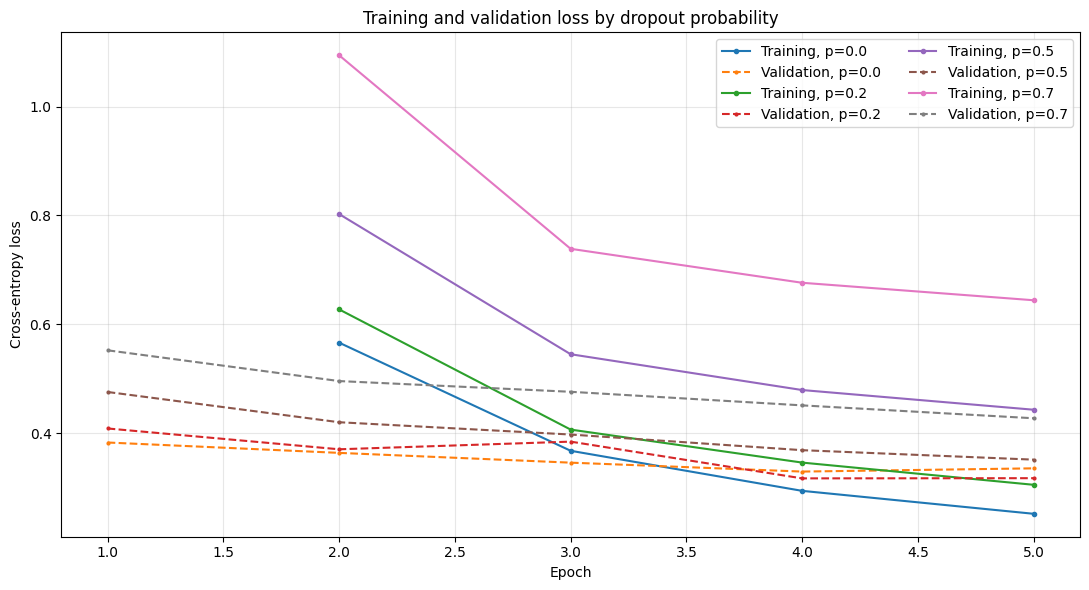

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
for p in DROPOUT_VALUES:
    h = histories[p]
    ax.plot(h["epoch"], h["train_loss"], marker="o", markersize=3,
            linestyle="-", label=f"Training, p={p:.1f}")
    ax.plot(h["epoch"], h["val_loss"], marker=".", markersize=4,
            linestyle="--", label=f"Validation, p={p:.1f}")
ax.set_title("Training and validation loss by dropout probability")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure1_loss_curves.png", dpi=300, bbox_inches="tight")
plt.show()


*Figure 1. Training (solid lines) and validation (dashed lines) cross-entropy loss by epoch for dropout probabilities 0.0, 0.2, 0.5, and 0.7. The curves show [describe the actual observed trend].*

## 11. Figure 2 — Validation accuracy

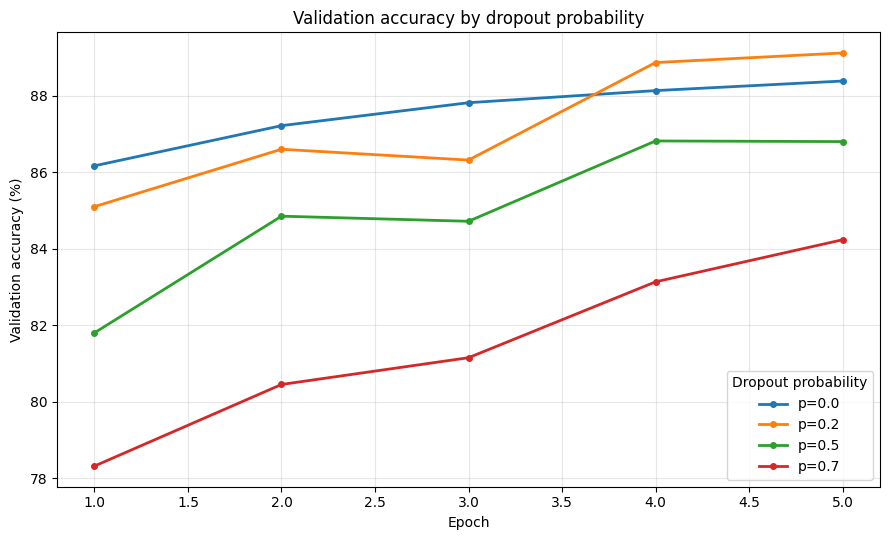

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for p in DROPOUT_VALUES:
    h = histories[p]
    ax.plot(h["epoch"], h["val_acc"] * 100, marker="o", linewidth=2,
            markersize=4, label=f"p={p:.1f}")
ax.set_title("Validation accuracy by dropout probability")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.legend(title="Dropout probability")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure2_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()


 *Figure 2. Validation accuracy by epoch for the four dropout probabilities. The highest observed validation accuracy was [X%] with p=[value] at epoch [N].*

## 12. Figure 3 — Best validation accuracy comparison

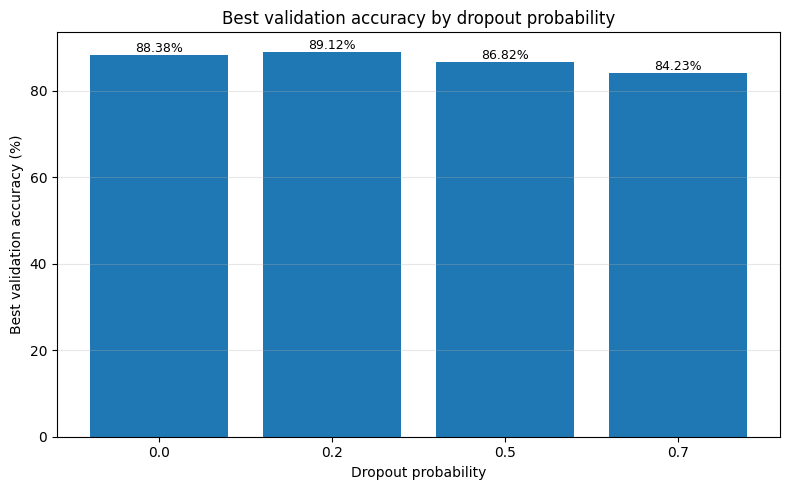

,dropout,best_epoch_by_val_accuracy,best_val_accuracy,val_loss_at_best_accuracy,final_train_loss,final_val_loss,final_train_accuracy,final_val_accuracy,training_seconds
0,0.0,5,0.8838,0.3352,0.2517,0.3352,0.9078,0.8838,143.8
1,0.2,5,0.8912,0.3171,0.3049,0.3171,0.8874,0.8912,145.2
2,0.5,4,0.8682,0.3686,0.4429,0.3512,0.8322,0.8680,157.6
3,0.7,5,0.8423,0.4272,0.6441,0.4272,0.7581,0.8423,147.0


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(results_df["dropout"].map(lambda x: f"{x:.1f}"),
              results_df["best_val_accuracy"] * 100)
ax.set_title("Best validation accuracy by dropout probability")
ax.set_xlabel("Dropout probability")
ax.set_ylabel("Best validation accuracy (%)")
ax.grid(axis="y", alpha=0.3)
for bar, value in zip(bars, results_df["best_val_accuracy"] * 100):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{value:.2f}%", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure3_best_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

display(results_df[[
    "dropout", "best_epoch_by_val_accuracy", "best_val_accuracy",
    "val_loss_at_best_accuracy", "final_train_loss", "final_val_loss",
    "final_train_accuracy", "final_val_accuracy", "training_seconds"
]].round(4))


**Caption template:** *Figure 3. Highest validation accuracy observed during the fixed 15-epoch run for each dropout probability. This comparison uses validation metrics only; it is not a claim about test-set performance.*

## 13. Generalization-gap analysis

In [ ]:
gap_df = results_df[[
    "dropout", "final_train_accuracy", "final_val_accuracy",
    "final_train_loss", "final_val_loss"
]].copy()
gap_df["accuracy_gap_percentage_points"] = (
    gap_df["final_train_accuracy"] - gap_df["final_val_accuracy"]
) * 100
display(gap_df.round(4))


,dropout,final_train_accuracy,final_val_accuracy,final_train_loss,final_val_loss,accuracy_gap_percentage_points
0,0.0,0.9078,0.8838,0.2517,0.3352,2.3967
1,0.2,0.8874,0.8912,0.3049,0.3171,-0.3767
2,0.5,0.8322,0.8680,0.4429,0.3512,-3.5800
3,0.7,0.7581,0.8423,0.6441,0.4272,-8.4233


The final accuracy gap is a diagnostic, not a complete definition of overfitting. Interpret it together with the loss curves and absolute validation performance. A smaller gap can occur because training performance worsens, so it is not automatically evidence of a better model.

## 14. Optional final test evaluation

Run this section **only after choosing a dropout probability using validation metrics**. It retrains the selected configuration on the full official training split and evaluates the official test set once. The test score should be reported as a final held-out estimate, not used to change the selected configuration.

The full-training retrain includes the images used for validation during the comparison, so the selected dropout value is chosen first using the fixed validation comparison.

In [ ]:
RUN_FINAL_TEST_EVALUATION = False  # change to True after completing validation-based selection

if RUN_FINAL_TEST_EVALUATION:
    best_row = results_df.loc[results_df["best_val_accuracy"].idxmax()]
    selected_dropout = float(best_row["dropout"])
    print(f"Selected from validation results: dropout={selected_dropout:.1f}")

    final_hp = replace(BASE_HP, dropout=selected_dropout, train_subset=None)
    L.seed_everything(final_hp.seed, workers=True)
    final_dm = FashionMNISTDataModule(final_hp)
    final_model = LitClassifier(final_hp)
    final_trainer = L.Trainer(
        max_epochs=final_hp.max_epochs,
        accelerator="auto",
        devices=1,
        deterministic=True,
        logger=False,
        enable_checkpointing=False,
        enable_progress_bar=True,
        enable_model_summary=False,
    )
    final_trainer.fit(final_model, datamodule=final_dm)
    test_results = final_trainer.test(final_model, datamodule=final_dm, verbose=False)
    display(pd.DataFrame(test_results))
else:
    print("Skipped. Set RUN_FINAL_TEST_EVALUATION=True only after validation-based selection.")


Skipped. Set RUN_FINAL_TEST_EVALUATION=True only after validation-based selection.


## 15. Interpretation worksheet — answer using your own results

Complete these prompts after reviewing the generated metrics and figures. Do not fill them with assumptions.

1. **Best validation result:** Which dropout setting reached the highest validation accuracy? Report the exact percentage and epoch.
2. **Evidence of overfitting:** Did any configuration show training loss decreasing while validation loss plateaued or increased? Point to the relevant epochs and values.
3. **Effect of dropout strength:** Did increasing dropout reduce the train/validation gap? Did it slow learning or reduce validation performance?
4. **Theory versus observation:** Did the results support your expectation that dropout may improve generalization? Cite specific values from your run.
5. **Limitations:** This experiment uses one seed, one CNN, one dataset, and 15 epochs. Differences may be affected by randomness, hardware, and the chosen architecture.
6. **Next step:** Repeat all four settings across three to five seeds and report mean ± standard deviation. That would help distinguish a consistent effect from seed-to-seed variation.

### Results paragraph template

> The highest validation accuracy observed in this experiment was **[X%]** at dropout probability **[p]**, reached at epoch **[N]**. The no-dropout baseline achieved **[Y%]**. The loss curves showed **[describe the actual pattern]**. These results [support/partly support/do not support] the expectation that dropout can improve generalization because **[explain using measured evidence]**. Since each setting was run with one seed, these findings should be treated as evidence from a controlled small-scale experiment rather than a universal conclusion.


## 16. Exported artifacts and reproducibility

The output directory contains per-run CSV files, a combined learning-curve CSV, a summary table, and the three figures. Upload the notebook and relevant artifacts to the same GitHub repository as your blog post, and link to the notebook from the post.

In [ ]:
print("Generated files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {path} ({path.stat().st_size:,} bytes)")

print("\nSuggested GitHub repository structure:")
print("your-repository/")
print("├── dropout_fashion_mnist.ipynb")
print("├── dropout_experiment_outputs/")
print("│   ├── figure1_loss_curves.png")
print("│   ├── figure2_validation_accuracy.png")
print("│   ├── figure3_best_validation_accuracy.png")
print("│   ├── all_learning_curves.csv")
print("│   └── dropout_results_summary.csv")
print("└── README.md")


Generated files:
- dropout_experiment_outputs/all_learning_curves.csv (1,805 bytes)
- dropout_experiment_outputs/dropout_results_summary.csv (700 bytes)
- dropout_experiment_outputs/figure1_loss_curves.png (300,321 bytes)
- dropout_experiment_outputs/figure2_validation_accuracy.png (188,882 bytes)
- dropout_experiment_outputs/figure3_best_validation_accuracy.png (100,564 bytes)
- dropout_experiment_outputs/history_dropout_0.0.csv (497 bytes)
- dropout_experiment_outputs/history_dropout_0.2.csv (501 bytes)
- dropout_experiment_outputs/history_dropout_0.5.csv (498 bytes)
- dropout_experiment_outputs/history_dropout_0.7.csv (492 bytes)

Suggested GitHub repository structure:
your-repository/
├── dropout_fashion_mnist.ipynb
├── dropout_experiment_outputs/
│   ├── figure1_loss_curves.png
│   ├── figure2_validation_accuracy.png
│   ├── figure3_best_validation_accuracy.png
│   ├── all_learning_curves.csv
│   └── dropout_results_summary.csv
└── README.md


## 17. References

1. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting.* Journal of Machine Learning Research, 15, 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html
2. PyTorch documentation. *torch.nn.Dropout.* https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html
3. Xiao, H., Rasul, K., & Vollgraf, T. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* https://arxiv.org/abs/1708.07747
4. PyTorch Lightning documentation. https://lightning.ai/docs/pytorch/stable/

